# Release timing

Question: which day and time should VELORA release its debut MV?

YouTube only gives total views today, not views in the first 24 hours. So I compare **views per day**, and compare each MV with the other MVs of the same group (a big group always gets more views).

In [48]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/videos.csv")
df["published_at"] = pd.to_datetime(df["published_at"])
df["collected_at"] = pd.to_datetime(df["collected_at"])

print(len(df), "videos")

8079 videos


## 1. Keep only the music videos

Keep videos with "MV" or "M/V" in the title, longer than 2 minutes. Remove teasers, reactions, behind the scenes and dance videos.

In [49]:
for g in ["PiXXiE", "VIIS", "ALALA"]:
    print("==", g)
    top = df[(df["group"] == g) & (df["duration_sec"] > 120)]
    top = top.sort_values("views", ascending=False).head(8)
    for t in top["title"]:
        print("  ", t)

== PiXXiE
   MABELZ PiXXiE x XX - heartstopper | DANCE PERFORMANCE
   PiXXiE - Golden | Live at PiXXiE Tales Concert : The Enchanted Ceremony
   PiXXiE - ชอบไปหมด (Way Too Cute) & ติดฝน (rain) | LIVE SESSION
   PiXXiE - FEAT | DANCE PERFORMANCE
   PiXXiE - FEAT | DANCE PRACTICE (MOVING VER.)
   PiXXiE - ติดฝน (rain) VISUALIZER PIANO VER. | OFFICIAL KARAOKE
   You Are My Light (有你在) - Zhao Lusi's version (PiXXiE Cover)
   INGKHO PiXXiE x Dome Jaruwat - สนทนา (Deep Talk) | LIVE SESSION
== VIIS
   VIIS ‘เจ็บนิด…นิด’ | Dance Practice
   จีบเอาสิคะ - VIIS | VIISUALIZER VIDEO
   VIIS ‘รักยังไม่ต้องการ’ | Dance Practice
   VIIS ‘MIRROR MIRROR’ | Dance Practice (Moving Ver.)
   VIIS ‘CHOP CHOP’ | Dance Practice (Moving Ver.)
   VIIS ‘ร้ายก็ได้ (Don't Mind)’ Dance Practice
   VIIS ‘เล่นไม่คิด (Thoughtless)’ Dance Practice
   VIIS ‘Barbie (Oops! Oops!)’ Dance Practice (FIX Ver.)
== ALALA
   ALALA - ร้องไห้ดังๆ (Executive Prod. by URBOYTJ) (Studio Version - Dance Practice)
   ‘Burning Snow’ ALALA

In [50]:
title = df["title"].str.lower()

has_mv = title.str.contains(r"\bm/?v\b|music video", regex=True)
long_video = df["duration_sec"] > 120
not_extra = ~title.str.contains(
    r"teaser|react|behind|making|practice|choreography|dance|performance|\blive\b|bts|ver\.|recap|storytelling|world|ep\.|vlog|days? with|ใน mv|การถ่ายทำ|ตามติด|เกาะติด|หนึ่งวัน",
    regex=True,
)

mvs = df[has_mv & long_video & not_extra].copy()

print(len(mvs), "MVs")
mvs["group"].value_counts()

69 MVs


group
4EVE         33
Pretzelle    19
MXFRUIT      10
FELIZZ        5
EMPRESS       2
Name: count, dtype: int64

In [51]:
mvs.sort_values("views")[["group", "title", "views"]].head(15)

,group,title,views
5748,MXFRUIT,MXFRUIT 'Heart Poppin'' OFFICIAL MV,212642
5094,Pretzelle,เมื่อโลกนี้มีเธอ (I'M GLAD) OST เล่ห์เกมรัก - ...,220128
5738,MXFRUIT,MXFRUIT 'เดาสิ! (Guess What ?)' OFFICIAL MV,395867
5769,MXFRUIT,MXFRUIT 'ต้านไม่ไหว (magnetize)' FT.XX | OFFIC...,430205
4928,Pretzelle,ไม่มีกั๊กหรอก (UNLIMITED) PRETZELLE Feat. 54 E...,467001
2092,4EVE,LazLOOK x 4EVE - LalaLOOK | Official MV,504895
5726,MXFRUIT,MXFRUIT 'UNIVERSE' OFFICIAL MV,506988
5777,MXFRUIT,MXFRUIT ‘so good so bad’ OFFICIAL MV,581211
6992,EMPRESS,EMPRESS - Too L8 [Official MV],617213
5757,MXFRUIT,MXFRUIT 'รักเธอใหม่ได้หรือเปล่า (one more chan...,743321


Check some titles to make sure they are real MVs.

In [52]:
mvs[["group", "title", "published_at", "views"]].sample(15, random_state=1)

,group,title,published_at,views
6992,EMPRESS,EMPRESS - Too L8 [Official MV],2024-07-24 18:30:07+07:00,617213
2426,4EVE,4EVE - LIKE A BLING (Prod. by BOTCASH) - OFFIC...,2021-03-28 10:00:22+07:00,12981645
2297,4EVE,4EVE - ข้อยกเว้น (EXCEPTIONAL) Prod. by Noth &...,2022-05-26 18:00:11+07:00,19763578
4708,Pretzelle,Catch It! - PRETZ [Official Music Video],2024-08-30 20:00:16+07:00,1240511
7325,FELIZZ,มีแมวไหม (Cat Me If You Can) - FELIZZ Feat. LE...,2026-06-05 20:00:06+07:00,890358
4990,Pretzelle,ก็เธอน่ะน่ารัก (BABY BOY) - PRETZELLE [OFFICIA...,2022-03-30 20:00:12+07:00,1842333
4701,Pretzelle,ซัดสักที (KNOCK OUT!) - PRETZELLE [OFFICIAL MV],2024-09-23 20:00:08+07:00,1168212
5769,MXFRUIT,MXFRUIT 'ต้านไม่ไหว (magnetize)' FT.XX | OFFIC...,2024-07-10 19:00:08+07:00,430205
5076,Pretzelle,ต้องชอบแค่ไหน (FIRST LOVE) - PRETZELLE [OFFICI...,2021-02-08 19:00:12+07:00,24308040
686,4EVE,4EVE - เปิ๊ดสะก๊าด | OFFICIAL MV,2025-12-17 18:00:07+07:00,4727260


## 2. Views per day

- Remove MVs younger than 30 days (views are still going up fast)
- views per day = views / days since release
- score = views per day / median of that group. Score 1.5 means 50% better than normal for that group

In [53]:
mvs["days_since"] = (mvs["collected_at"] - mvs["published_at"]).dt.days
mvs = mvs[mvs["days_since"] >= 30].copy()

mvs["views_per_day"] = mvs["views"] / mvs["days_since"]

group_median = mvs.groupby("group")["views_per_day"].transform("median")
mvs["score"] = mvs["views_per_day"] / group_median

print(len(mvs), "MVs left")

69 MVs left


## 3. Day of the week

In [54]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
mvs["day"] = mvs["published_at"].dt.day_name()

by_day = mvs.groupby("day")["score"].agg(["median", "count"]).reindex(day_order)
by_day

,median,count
day,,
Monday,0.928972,6
Tuesday,0.799672,1
Wednesday,1.131576,20
Thursday,1.391940,21
Friday,0.912189,14
Saturday,0.526215,2
Sunday,0.787694,5


In [55]:
no_4eve = mvs[mvs["group"] != "4EVE"]
no_4eve.groupby("day")["score"].agg(["median", "count"]).reindex(day_order)

,median,count
day,,
Monday,2.512830,4.0
Tuesday,0.799672,1.0
Wednesday,1.000000,12.0
Thursday,1.033610,10.0
Friday,0.864967,9.0
Saturday,NaN,NaN
Sunday,NaN,NaN


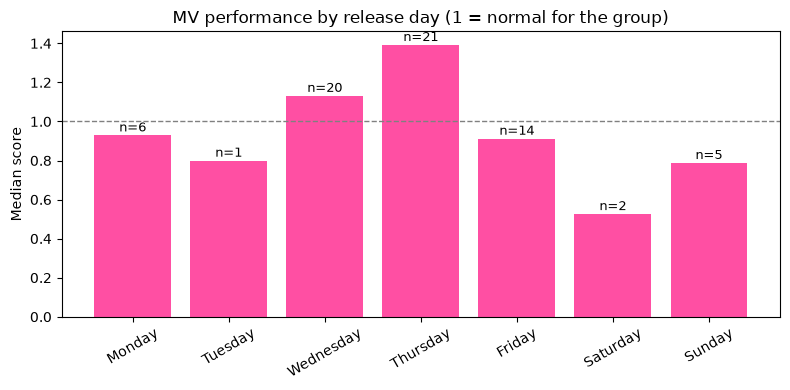

In [56]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_day.index, by_day["median"], color="#FF4FA3")
ax.axhline(1, color="gray", linestyle="--", linewidth=1)

for i, (score, count) in enumerate(zip(by_day["median"], by_day["count"])):
    if pd.notna(score):
        ax.text(i, score + 0.02, f"n={count}", ha="center", fontsize=9)

ax.set_title("MV performance by release day (1 = normal for the group)")
ax.set_ylabel("Median score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("../reports/figures/release_day.png", dpi=150)
plt.show()

## 4. Time of day (Thai time)

Only show hours with at least 3 MVs. One or two MVs is not enough to say anything.

In [57]:
mvs["hour"] = mvs["published_at"].dt.hour

by_hour = mvs.groupby("hour")["score"].agg(["median", "count"])
by_hour = by_hour[by_hour["count"] >= 3]
by_hour

,median,count
hour,,
11,0.926223,5
12,0.387994,3
16,0.932281,3
17,2.511013,3
18,1.511528,9
19,0.941217,23
20,1.000000,19


In [58]:
no_4eve.groupby(no_4eve["published_at"].dt.hour)["score"].agg(["median", "count"])

,median,count
published_at,,
8,1.184822,1
12,0.387994,1
16,0.932281,3
17,2.511013,3
18,0.799672,3
19,1.118417,6
20,1.000000,19


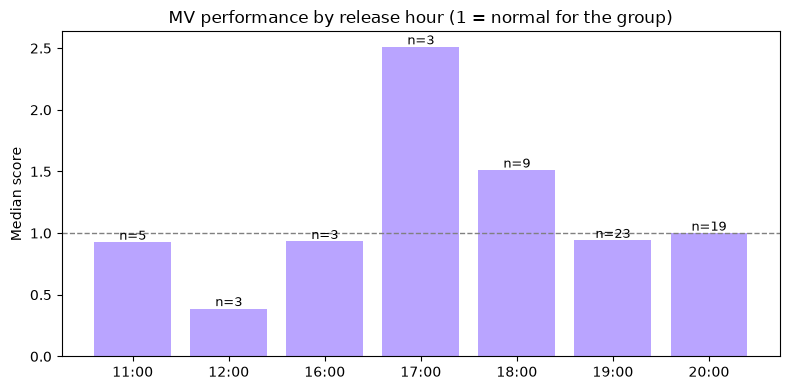

In [59]:
fig, ax = plt.subplots(figsize=(8, 4))
labels = [f"{h:02d}:00" for h in by_hour.index]
ax.bar(labels, by_hour["median"], color="#B9A4FF")
ax.axhline(1, color="gray", linestyle="--", linewidth=1)

for i, (score, count) in enumerate(zip(by_hour["median"], by_hour["count"])):
    ax.text(i, score + 0.02, f"n={count}", ha="center", fontsize=9)

ax.set_title("MV performance by release hour (1 = normal for the group)")
ax.set_ylabel("Median score")
plt.tight_layout()
plt.savefig("../reports/figures/release_hour.png", dpi=150)
plt.show()

## 5. When do other groups release?

If most groups release at the same time, VELORA has more competition in that slot.

In [60]:
crosstab = pd.crosstab(mvs["day"], mvs["hour"]).reindex(day_order).fillna(0).astype(int)
crosstab

hour,8,9,10,11,12,16,17,18,19,20
day,,,,,,,,,,
Monday,0,0,0,0,0,0,0,0,4,2
Tuesday,0,0,0,0,0,0,0,1,0,0
Wednesday,1,0,0,0,0,0,2,4,10,3
Thursday,0,0,0,1,1,3,0,4,5,7
Friday,0,1,0,0,1,0,1,0,4,7
Saturday,0,0,1,0,1,0,0,0,0,0
Sunday,0,0,1,4,0,0,0,0,0,0


## Findings

**Release day and time have only a small effect on MV views.**

- At first, Thursday (1.39) and 18:00 (1.51) looked best. But 4EVE has 33 of 69 MVs. Without 4EVE, both results go away (Thursday 1.03, 18:00 0.80)
- **Stable results** (same with and without 4EVE):
  - Friday is a little below normal (0.91 and 0.86)
  - 19:00 and 20:00 are about normal (19:00: 0.94 and 1.12, 20:00: 1.00 and 1.00)
- **Most common release slot:** Wednesday 19:00 (10 MVs). Groups other than 4EVE mostly release at 20:00

**Decision for VELORA:** release the debut MV on **Thursday at 19:00**.
- Timing will not add many views, so pick a safe slot with less competition
- Thursday and 19:00 are never clearly below normal
- Thursday 19:00 has 5 competing MVs, compared with 10 on Wednesday 19:00

**Hypothesis check:** the artist brief guessed Friday evening is best. The data does not support this.

**What this means:** timing is not the main driver of views. The next notebook looks at content type (Shorts vs MV).

**Limitations**
- Views per day is not the same as first 24 hours views
- Only 5 groups. PiXXiE, VIIS and ALALA post their MVs on other channels, so they are not included
- 4EVE has 33 of 69 MVs, so every result was also checked without 4EVE
- Some slots have very few MVs (17:00 has 3), so they are not used for the decision

In [63]:
mvs.to_csv("../data/processed/mvs.csv", index=False)
print("saved")

saved
